# 04 — Noise, significance, and how long you must wait

*Weeks 5–6. This is the heart of the project.*

This notebook distinguishes two quantities: **expected significance**, which defines the smooth headline sensitivity curve, and **observed significance**, which fluctuates because a simulated measurement is a Poisson random draw.


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../code'))
import numpy as np
import matplotlib.pyplot as plt
import muography as mg
import project_config as cfg
import student_analysis as sa
print('ready')


ready


## Poisson counting

If the expected number of events is N, the typical statistical spread is about √N. Use the fixed reference seed while developing so that your noisy figures are reproducible.


In [2]:
rng = np.random.default_rng(cfg.REFERENCE_SEED)
for mean in [10, 100, 1000, 10000]:
    draws = rng.poisson(mean, size=5000)
    print(f'expect {mean:6d}   actual spread = {draws.std():8.1f}   '
          f'(sqrt of mean = {np.sqrt(mean):8.1f})   relative = {draws.std()/mean:6.2%}')


expect     10   actual spread =      3.2   (sqrt of mean =      3.2)   relative = 32.15%
expect    100   actual spread =      9.9   (sqrt of mean =     10.0)   relative =  9.95%
expect   1000   actual spread =     31.7   (sqrt of mean =     31.6)   relative =  3.17%
expect  10000   actual spread =    100.9   (sqrt of mean =    100.0)   relative =  1.01%


## Build the baseline expectation maps

This notebook deliberately rebuilds its inputs from the shared functions. You can run it from a fresh kernel without running notebook 03 first.


In [3]:
target = mg.Pyramid(
    base=cfg.PYRAMID_BASE_M, height=cfg.PYRAMID_HEIGHT_M,
    density=cfg.ROCK_DENSITY_G_CM3, void_centre=cfg.VOID_CENTRE_M,
    void_radius=cfg.VOID_RADIUS_M, has_void=True,
)
target0 = target.without_void()
detector = np.array(cfg.DETECTOR_POSITION_M, dtype=float)
expected_1d, ax_deg, ay_deg = sa.expected_counts(target, detector, 1.0)
expected_1d_0, _, _ = sa.expected_counts(target0, detector, 1.0)
expected_30d, _, _ = sa.expected_counts(target, detector, 30.0)
expected_30d_0, _, _ = sa.expected_counts(target0, detector, 30.0)


### YOUR TURN — make the images noisy

Use `mg.poisson_counts` with the reference seed to make 1-day and 30-day observed count maps. Plot each observed map divided by the corresponding **expected no-void** map.


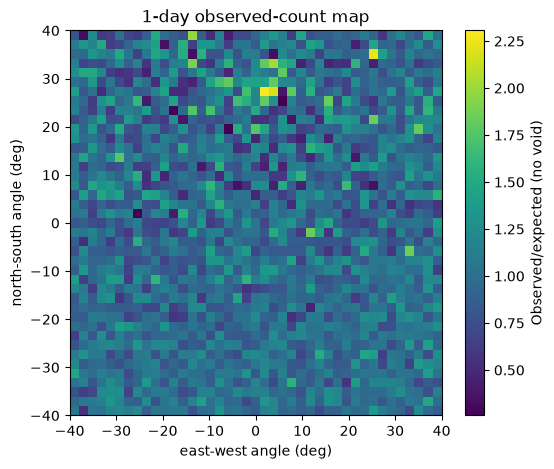

In [4]:
exp_v_1d, ax_deg, ay_deg = sa.expected_counts(target, detector, 1.0)
exp_nv_1d, _, _ = sa.expected_counts(target0, detector, 1.0)

exp_v_30d = exp_v_1d * 30.0
exp_nv_30d = exp_nv_1d * 30.0

rng = np.random.default_rng(cfg.REFERENCE_SEED)
observed_1d = mg.poisson_counts(exp_v_1d, rng)
observed_30d = mg.poisson_counts(exp_v_30d, rng)


counts_void_1day, ax_deg_1day, ay_deg_1day = sa.expected_counts(target0, detector, days=1)

plt.figure (figsize=(6,5))
plt.imshow(
    observed_1d/exp_nv_1d,
    extent = [ax_deg_1day.min(), ax_deg_1day.max(), ay_deg_1day.min(), ay_deg_1day.max()],
    origin = 'lower',
    aspect = 'auto',
    cmap = 'viridis'
)

plt.xlim(-40,40)
plt.ylim (-40, 40)
plt.colorbar(label = 'Observed/expected (no void)')
plt.xlabel('east-west angle (deg)')
plt.ylabel ('north-south angle (deg)')
plt.title ('1-day observed-count map')
plt.show()

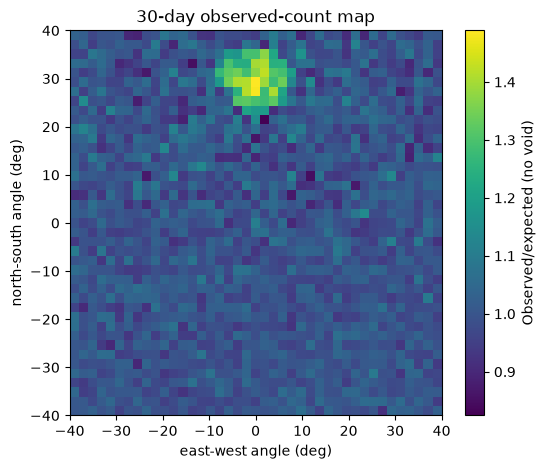

In [5]:
counts_void_30day, ax_deg_30day, ay_deg_30day = sa.expected_counts(target0, detector, days=30)

plt.figure (figsize=(6,5))
plt.imshow(
    observed_30d/exp_nv_30d,
    extent = [ax_deg_30day.min(), ax_deg_30day.max(), ay_deg_30day.min(), ay_deg_30day.max()],
    origin = 'lower',
    aspect = 'auto',
    cmap = 'viridis'
)

plt.xlim(-40,40)
plt.ylim (-40, 40)
plt.colorbar(label = 'Observed/expected (no void)')
plt.xlabel('east-west angle (deg)')
plt.ylabel ('north-south angle (deg)')
plt.title ('30-day observed-count map')
plt.show()

## Observed significance

`mg.significance(observed, expected_no_void)` compares one noisy observation with the no-chamber expectation. It fluctuates from run to run. For this educational project, 5σ is a predefined headline threshold; it is not a complete discovery test for a real experiment.

### YOUR TURN

Make significance maps for 1 day and 30 days. Record the random seed in your figure caption or log. Do not define the official exposure time from the largest noisy pixel.


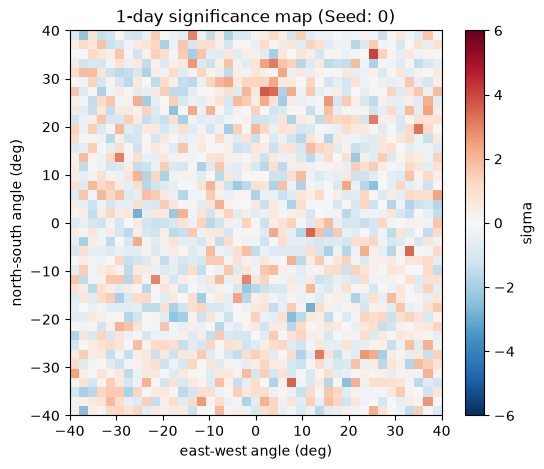

In [6]:
S1_obs = mg.significance(observed_1d, exp_nv_1d)
S30_obs = mg.significance(observed_30d, exp_nv_30d)

plt.figure (figsize=(6,5))
plt.imshow(
    S1_obs,
    extent = [ax_deg.min(), ax_deg.max(), ay_deg.min(), ay_deg.max()],
    origin = 'lower',
    aspect = 'auto',
    cmap = 'RdBu_r',
    vmin = -6,
    vmax = 6
)

plt.xlim(-40,40)
plt.ylim (-40, 40)
plt.colorbar(label = 'sigma')
plt.xlabel('east-west angle (deg)')
plt.ylabel ('north-south angle (deg)')
plt.title (f'1-day significance map (Seed: {cfg.REFERENCE_SEED})')
plt.show()

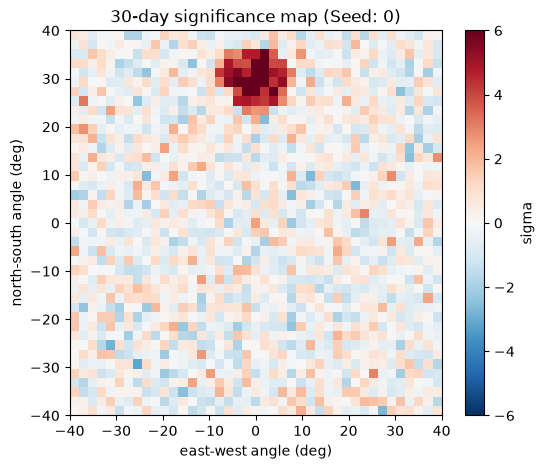

In [7]:

plt.figure (figsize=(6,5))
plt.imshow(
    S30_obs,
    extent = [ax_deg.min(), ax_deg.max(), ay_deg.min(), ay_deg.max()],
    origin = 'lower',
    aspect = 'auto',
    cmap = 'RdBu_r',
    vmin = -6,
    vmax = 6
)

plt.xlim(-40,40)
plt.ylim (-40, 40)
plt.colorbar(label = 'sigma')
plt.xlabel('east-west angle (deg)')
plt.ylabel ('north-south angle (deg)')
plt.title (f'30-day significance map (Seed: {cfg.REFERENCE_SEED})')
plt.show()

## The main result: expected significance

The official headline curve uses **expected significance**:

`S_expected = (expected_with_void - expected_without_void) / sqrt(expected_without_void)`

This is deterministic for fixed parameters and follows the expected `√T` scaling. It is the correct quantity for a reproducible exposure-time estimate in this simplified project.


In [8]:
days_list = np.array([1, 2, 3, 5, 7, 10, 14, 21, 30, 45, 60, 90, 120, 180], dtype=float)
# Choose the signal pixel once from the baseline expected signal.
base_mu_v, _, _ = sa.expected_counts(target, detector, 1.0)
base_mu_0, _, _ = sa.expected_counts(target0, detector, 1.0)
signal_idx = np.unravel_index(np.argmax(base_mu_v - base_mu_0), base_mu_v.shape)


S_expected = []
for days in days_list:
    mu_v, _, _ = sa.expected_counts(target, detector, days)
    mu_0, _, _ = sa.expected_counts(target0, detector, days)
    S_map = mg.expected_significance(mu_v, mu_0)
    S_expected.append(S_map[signal_idx])
S_expected = np.asarray(S_expected)
print('signal pixel:', signal_idx)
for d, s in zip(days_list, S_expected):
    print(f'{d:6.0f} days  expected S = {s:6.3f}')


signal pixel: (np.int64(35), np.int64(20))
     1 days  expected S =  1.370
     2 days  expected S =  1.937
     3 days  expected S =  2.372
     5 days  expected S =  3.062
     7 days  expected S =  3.624
    10 days  expected S =  4.331
    14 days  expected S =  5.125
    21 days  expected S =  6.276
    30 days  expected S =  7.502
    45 days  expected S =  9.187
    60 days  expected S = 10.609
    90 days  expected S = 12.993
   120 days  expected S = 15.003
   180 days  expected S = 18.375


### YOUR TURN — plot the exposure curve

Plot `S_expected` against days on a logarithmic x-axis. Add horizontal lines at 3σ and 5σ. Determine the first crossing of 5σ by interpolation between the nearest scan points.

Your headline sentence should be:

> **For the baseline 0.25 m² detector and 10 m radius chamber, the expected signal reaches 5σ after approximately ___ days under the project's simplified model.**

Do not add an uncertainty to this number unless your mentor gives you a defined procedure for estimating one.


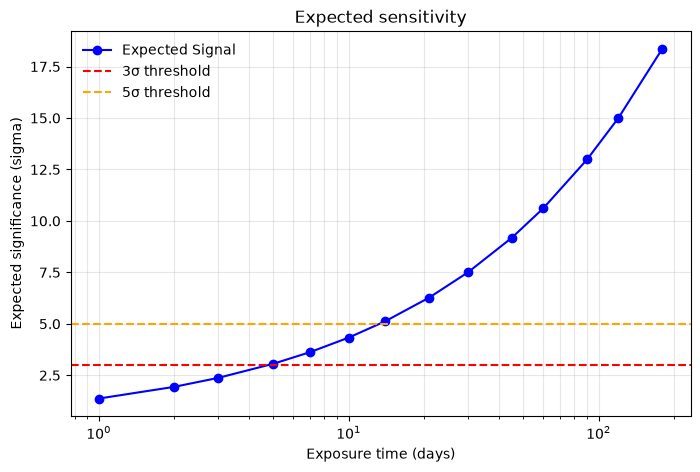

In [ ]:
# YOUR TURN

plt.figure (figsize=(8,5));
plt.semilogx (days_list, S_expected, marker= 'o', color = 'blue', label = 'Expected Signal')

plt.axhline (3.0, color = 'red', linestyle = '--', label = '3σ threshold')
plt.axhline (5.0, color = 'orange', linestyle = '--', label = '5σ threshold')

days_at_5sigma = np.interp (5.0, S_expected, days_list)

plt.title ('Expected sensitivity')
plt.ylabel ('Expected significance (sigma)')
plt.xlabel ('Exposure time (days)')

plt.grid(alpha=0.3, which='both')
plt.legend(frameon=False)

plt.show()

print ()


## Why the noisy curve is different

If you repeat the analysis with Poisson observations, individual significance values will jitter around the expected curve. That is not a bug. It is the statistical fluctuation the simulation is designed to teach.

The previous version of this project used the maximum noisy pixel as the headline statistic. We no longer do that: choosing a pixel because it fluctuated upward introduces a selection bias. You may explore the maximum as a separate exercise, but it is not the official exposure-time definition.


## Optional: the no-void control

Run the same noisy significance calculation on `target.without_void()`. This gives you a concrete demonstration that a noise-only image can contain locally surprising pixels. In your report, call this a **control** or **null simulation**, not a discovery test.


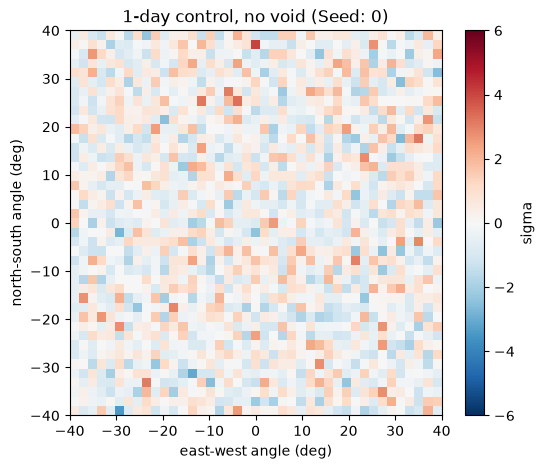

In [10]:
# YOUR TURN (optional)

nv_1d = mg.poisson_counts(exp_nv_1d, rng)
nv_30d = mg.poisson_counts(exp_nv_30d, rng)

S1_nv = mg.significance(nv_1d, exp_nv_1d)
S30_nv = mg.significance(nv_30d, exp_nv_30d)

plt.figure(figsize=(6,5))
plt.imshow (
    S1_nv,
    extent= [ax_deg.min(), ax_deg.max(), ay_deg.min(), ay_deg.max()],
    origin= 'lower',
    aspect='auto',
    cmap= 'RdBu_r',
    vmin = -6,
    vmax = 6
)
plt.xlim (-40, 40)
plt.ylim (-40, 40)
plt.colorbar(label = 'sigma')
plt.xlabel ('east-west angle (deg)')
plt.ylabel ('north-south angle (deg)')
plt.title (f'1-day control, no void (Seed: {cfg.REFERENCE_SEED})')
plt.show()

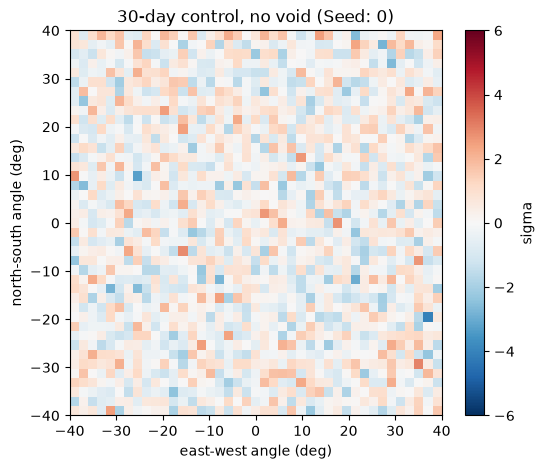

In [11]:
plt.figure(figsize=(6,5))
plt.imshow (
    S30_nv,
    extent= [ax_deg.min(), ax_deg.max(), ay_deg.min(), ay_deg.max()],
    origin= 'lower',
    aspect='auto',
    cmap= 'RdBu_r',
    vmin = -6,
    vmax = 6
)
plt.xlim (-40, 40)
plt.ylim (-40, 40)
plt.colorbar(label = 'sigma')
plt.xlabel ('east-west angle (deg)')
plt.ylabel ('north-south angle (deg)')
plt.title (f'30-day control, no void (Seed: {cfg.REFERENCE_SEED})')
plt.show()

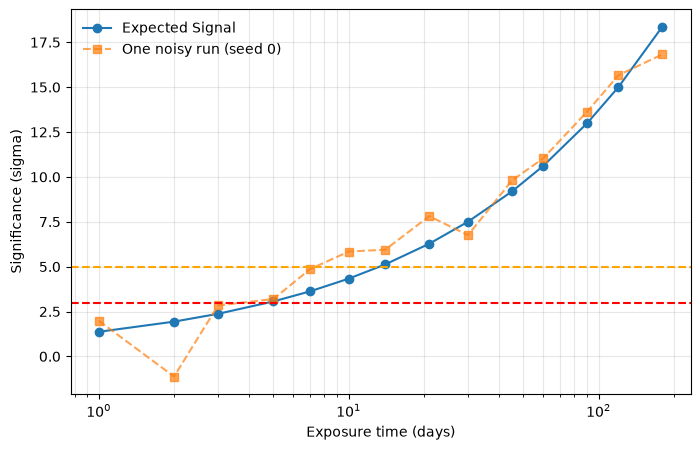

In [12]:
rng_c = np.random.default_rng(cfg.REFERENCE_SEED)
S_noisy = []
for d in days_list:
    mu_v = exp_v_1d[signal_idx] * d
    mu_0 = exp_nv_1d[signal_idx] * d
    S_noisy.append(mg.significance(rng_c.poisson(mu_v), mu_0))

plt.figure(figsize=(8, 5))
plt.semilogx(days_list, S_expected, 'o-', label='Expected Signal')
plt.semilogx(days_list, S_noisy, 's--', alpha=0.7, label=f'One noisy run (seed {cfg.REFERENCE_SEED})')
plt.axhline(3.0, ls='--', color='red'); plt.axhline(5.0, ls='--', color='orange')
plt.xlabel('Exposure time (days)'); plt.ylabel('Significance (sigma)')
plt.legend(frameon=False); plt.grid(alpha=0.3, which='both'); plt.show()

